In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR

from xgboost import XGBRegressor

In [2]:
df = pd.read_csv("../data/insurance.csv")

df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [3]:
df = pd.get_dummies(
    df,
    columns=["sex", "smoker", "region"],
    drop_first=True
)

X = df.drop("charges", axis=1)
y = df["charges"]

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [5]:
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(
        max_depth=5,
        random_state=42
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=300,
        max_depth=10,
        min_samples_split=5,
        random_state=42,
        n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    ),
    "XGBoost": XGBRegressor(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=3,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42
    )
}

In [6]:
results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    results.append({
        "Model": name,
        "R²": r2_score(y_test, predictions),
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions))
    })

In [7]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="R²",
    ascending=False
)

results_df

,Model,R²,MAE,RMSE
4,XGBoost,0.882139,2375.342386,4277.597610
3,Gradient Boosting,0.880606,2453.481502,4305.324830
2,Random Forest,0.869317,2524.023762,4504.256917
1,Decision Tree,0.833610,2930.767571,5082.505544
0,Linear Regression,0.783593,4181.194474,5796.284659


In [8]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [9]:
svr_model = SVR(
    kernel="rbf",
    C=1000,
    gamma="scale",
    epsilon=0.1
)

svr_model.fit(X_train_scaled, y_train)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive.The penalty is a squared l2. For an intuitive visualization of theeffects of scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1000
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm.If none is given, 'rbf' will be used. If a callable is given it isused to precompute the kernel matrix.For an intuitive visualization of different kernel typessee :ref:`sphx_glr_auto_examples_svm_plot_svm_regression.py`",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"epsilon epsilon: float, default=0.1Epsilon in the epsilon-SVR model. It specifies the epsilon-tubewithin which no penalty is associated in the training loss functionwith points predicted within a distance epsilon from the actualvalue. Must be non-negative.",0.1
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False
,"max_iter max_iter: int, default=-1Hard limit on iterations within solver, or -1 for no limit.",-1


In [10]:
svr_predictions = svr_model.predict(X_test_scaled)

svr_results = {
    "Model": "SVR",
    "R²": r2_score(y_test, svr_predictions),
    "MAE": mean_absolute_error(y_test, svr_predictions),
    "RMSE": np.sqrt(mean_squared_error(y_test, svr_predictions))
}

svr_results

{'Model': 'SVR',
 'R²': 0.7468874650882389,
 'MAE': 2800.214622541228,
 'RMSE': np.float64(6268.604307955492)}

In [11]:
results_df = pd.concat(
    [results_df, pd.DataFrame([svr_results])],
    ignore_index=True
)

results_df = results_df.sort_values(
    by="R²",
    ascending=False
)

results_df

,Model,R²,MAE,RMSE
0,XGBoost,0.882139,2375.342386,4277.597610
1,Gradient Boosting,0.880606,2453.481502,4305.324830
2,Random Forest,0.869317,2524.023762,4504.256917
3,Decision Tree,0.833610,2930.767571,5082.505544
4,Linear Regression,0.783593,4181.194474,5796.284659
5,SVR,0.746887,2800.214623,6268.604308


In [12]:
best_model_name = results_df.iloc[0]["Model"]

print("Best Model:", best_model_name)
print("Best R²:", results_df.iloc[0]["R²"])

Best Model: XGBoost
Best R²: 0.8821385454208167


In [13]:
best_model = models[best_model_name]

best_predictions = best_model.predict(X_test)

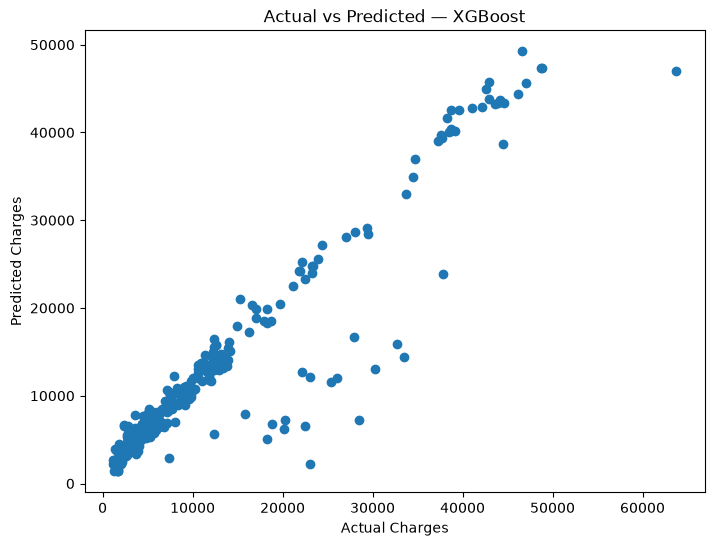

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_test, best_predictions)

plt.xlabel("Actual Charges")
plt.ylabel("Predicted Charges")
plt.title(f"Actual vs Predicted — {best_model_name}")

plt.show()

In [15]:
import joblib

joblib.dump(best_model, "../models/best_model.pkl")

['../models/best_model.pkl']

In [16]:
joblib.dump(scaler, '../models/scaler.pkl')

['../models/scaler.pkl']

In [17]:
import os

print('model saved:',os.path.exists('../models/best_model.pkl'))
print('scaler saved:', os.path.exists('../models/scaler.pkl'))

model saved: True
scaler saved: True
